# Fresh-preparation Hadamard phase estimation

Controlled powers turn an eigenphase into sine/cosine probabilities. This notebook reconstructs explicit gates and replays the recorded count data. Every modeled shot starts with fresh resets and an X-prepared product eigenstate; it does not retain a mixed target between experiments.

The ideal confidence argument assumes exact eigenstate preparation, controlled powers and IID trials. SDK gates and `atan2` recovery are numerical checks, with no physical or formal certificate. The published resource ledger charges every represented trial.

In [1]:
from pathlib import Path
from fractions import Fraction
import importlib.util, json, sys, os
root = Path.cwd()
if not (root / "src").is_dir() and (root.parent / "src").is_dir():
    root = root.parent
sys.path.insert(0, str(root / "src"))
records = root / "assets/generated/hadamard-qpe"
spec = importlib.util.spec_from_file_location("notebook_hadamard_record_verifier", root / "scripts/verify_hadamard_qpe.py")
verifier = importlib.util.module_from_spec(spec)
spec.loader.exec_module(verifier)
replay = verifier.verify_record(records)
assert replay["new_sampling_calls"] == replay["native_calls"] == 0
from openquantum.hadamard_qpe import (
    FringeCounts, build_experiment, check_experiment, recover_phase,
    protocol_ledger, circular_distance, shots_for_failure,
)
data = json.loads((records / "results.json").read_text())
print(replay["status"])
print("Historical producer:", replay["producer_source_commit"])
print("Current replay:", replay["current_replay_commit"])

verified_saved_numerical_record_current_guard_replay
Historical producer: def275c501c8c55a32e219674000b4199eaa16d4
Current replay: a3350e7f39cffd5a1ccc123d4b9b0a44c12f41e6


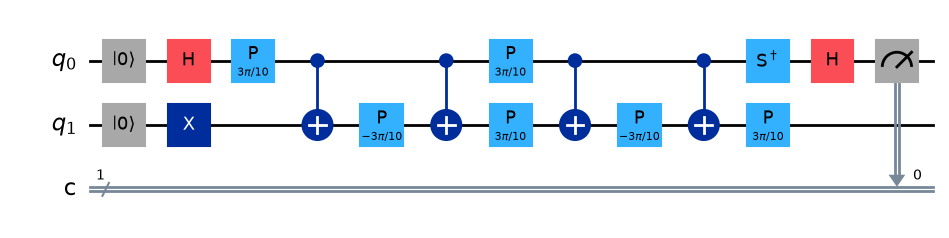

In [2]:
import matplotlib.pyplot as plt
phase, power = 0.3, 2
circuit = build_experiment(1, phase, power, "sin")
figure = circuit.draw(output="mpl", fold=32)
display(figure)
plt.close(figure)
assert circuit.count_ops()["p"] == 6
assert circuit.count_ops()["cx"] == 4
assert circuit.count_ops()["reset"] == 2

In [3]:
checks = [check_experiment(1, phase, 1 << j, basis)
          for j in range(6) for basis in ("cos", "sin")]
assert max(x["full_operator_max_error"] for x in checks) < 2e-11
assert max(x["probability_absolute_error"] for x in checks) < 2e-11
print("All powers are literal repeated controlled-P calls.")
print("Maximum probability residual:", max(x["probability_absolute_error"] for x in checks))

All powers are literal repeated controlled-P calls.
Maximum probability residual: 9.71445146547012e-16


In [4]:
from IPython.display import Markdown, display
for run in data["runs"]:
    counts = [FringeCounts(**c) for c in run["result"]["counts"]]
    recovered = recover_phase(counts)
    verifier.compare_recovery(run["result"], recovered)
    assert recovered["counts"] == run["result"]["counts"]
display(Markdown((records / "summary.md").read_text()))
print("Saved trial count:", data["simulation"]["modeled_fresh_trials_sampled"])
print("New binomial draws in this notebook: 0")

| Nominal phase | Seed | Recovered phase | Circular error | Status |
|---:|---:|---:|---:|---|
| 0.3 | 7 | 0.300417456 | 0.000417 | recovered_numerically |
| 0.3 | 19 | 0.299777766 | 0.000222 | recovered_numerically |
| 0.3 | 41 | 0.299983911 | 1.61e-05 | recovered_numerically |
| 0.995 | 7 | 0.994912128 | 8.79e-05 | recovered_numerically |
| 0.995 | 19 | 0.994771400 | 0.000229 | recovered_numerically |
| 0.995 | 41 | 0.995157613 | 0.000158 | recovered_numerically |
| 0.125 | 7 | 0.125347133 | 0.000347 | recovered_numerically |
| 0.125 | 19 | 0.125256766 | 0.000257 | recovered_numerically |
| 0.125 | 41 | 0.125317033 | 0.000317 | recovered_numerically |
| 0.5 | 7 | 0.499682967 | 0.000317 | recovered_numerically |
| 0.5 | 19 | 0.500196423 | 0.000196 | recovered_numerically |
| 0.5 | 41 | 0.500166228 | 0.000166 | recovered_numerically |


Saved trial count: 47376
New binomial draws in this notebook: 0


In [5]:
m = shots_for_failure(6, Fraction(1, 1200))
assert m == 329
ledger = protocol_ledger(1, 6, m)
assert ledger == data["common_per_output_ledger"]
whole = data["whole_study_modeled_workload"]
assert whole["complete_fresh_preparations"] == 47376
assert whole["shot_weighted_controlled_U_calls"] == 497448
print("Per-output ledger:", ledger)
print("Whole twelve-output study:", whole)
print("Physical estimation/synthesis remain unexecuted.")

Per-output ledger: {'target_qubits': 1, 'logical_qubits': 2, 'levels': 6, 'shots_per_fringe': 329, 'distinct_experiment_circuits': 12, 'complete_fresh_preparations': 3948, 'maximum_controlled_U_power': 32, 'shot_weighted_controlled_U_calls': 41454, 'source_gate_counts_all_trials': {'p': 124362, 'cx': 82908, 'h': 7896, 'x': 3948, 'sdg': 1974, 'reset': 7896, 'measure': 3948}, 'ideal_phase_radius_exact': '1/256', 'ideal_failure_upper_bound_exact': '4519976474872543820458068806409342980200633700644627369203618838552200459760454070014973003017675983548485852411509945897053924591626059180644060985282511417505572082774255173151109696781673722893729668942862714873733182772968288303806457492675804985125199244080652072271890868908135022685917180223333667004054849412310678023214340761461051626715599979151360000000000000000000000000000000/54955994930784092792548703438582531019520502442535905207798447813754509354507562641208228213066193080467595880371260806713877449184415661092484667815479693509181

## Ideal confidence and numerical scope

For each dyadic power, two independent sample proportions determine the complex signal. A probability error at most $1/8$ in both coordinates implies a phase-angle error smaller than $1/8$ cycles. Nearest circular lifts then give radius $1/(8k_{\max})$. Hoeffding plus a union bound supplies $4L\exp(-m/32)$ per output.

The code selects $m$ using an exact positive rational Taylor lower bound to $\exp(m/32)$, preserving a conservative reciprocal upper bound. The twelve predefined outputs share total ideal failure $0.01$ by allocating $1/1200$ per output. This exact arithmetic does not certify the floating-point inverse tangent, SDK realization, angle synthesis or hardware noise.

The original producer source is preserved separately from the current source's stricter floating-angle guard. Replay verifies that none of these canonical angles reach that guard, and retains the original counts, seeds and timing records.

To enable the optional controls in a local notebook kernel, set `os.environ["OPENQUANTUM_STATIC_BUILD"] = "0"` before running the final cell. The controls check fresh gate probabilities before drawing new local ideal counts; they do not alter the saved study. Static execution keeps this option disabled.

In [6]:
# Optional local-kernel controls. Static publication runs this branch disabled.
# Live counts are a new bounded ideal experiment, outside the frozen record.
if os.environ.get("OPENQUANTUM_STATIC_BUILD", "1") != "1":
    import ipywidgets as widgets
    from openquantum.hadamard_qpe import sample_counts
    @widgets.interact(phase=widgets.FloatSlider(value=.3, min=0, max=.999, step=.005),
                      levels=widgets.Dropdown(options=[3, 4, 6], value=4))
    def explore(phase, levels):
        probabilities = [min(1.0, max(0.0, check_experiment(1, phase, 1 << j, b)["zero_probability"]))
                         for j in range(levels) for b in ("cos", "sin")]
        shots = shots_for_failure(levels, Fraction(1, 100))
        counts = sample_counts(probabilities, levels, shots, seed=19)
        result = recover_phase(counts)
        print("New ideal local-kernel estimate:", result["phase_estimate"])
        print("Fresh represented trials:", 2 * levels * shots)
else:
    print("Static saved replay; local widgets require an enabled notebook kernel.")

Static saved replay; local widgets require an enabled notebook kernel.
